In [1]:
#Partie 1 — Explorer et vérifier les données

In [2]:
#1

In [3]:
import pandas as pd

In [4]:
df = pd.read_csv("transactions_TP2.csv")    

In [5]:

df.head()


,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


In [6]:
df.shape

(3045, 12)

In [8]:
df.dtypes

id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object

In [9]:
#2)

In [10]:
nombre_manqua= df.isna().sum()
pourcentage_manqua=df.isna().mean() * 100
table_manqua = pd.DataFrame({'Nombre de manquants':nombre_manqua,'Pourcentage': pourcentage_manqua})
table_manqua = table_manqua.sort_values(by='Nombre de manquants', ascending = False)
print(table_manqua)

                  Nombre de manquants  Pourcentage
canal                             159     5.221675
anciennete_mois                   137     4.499179
appareil                          122     4.006568
montant_dh                        110     3.612479
region                            103     3.382594
nb_ops_24h                         53     1.740558
id_operation                        0     0.000000
id_client                           0     0.000000
heure                               0     0.000000
international                       0     0.000000
resultat_enquete                    0     0.000000
fraude                              0     0.000000


In [11]:
#3

In [12]:
df["id_operation"].duplicated().sum()

np.int64(45)

In [13]:
# ona 45 repetition 
df = df.drop_duplicates(subset="id_operation")

In [148]:
df.shape[0]

3000

In [15]:
#4

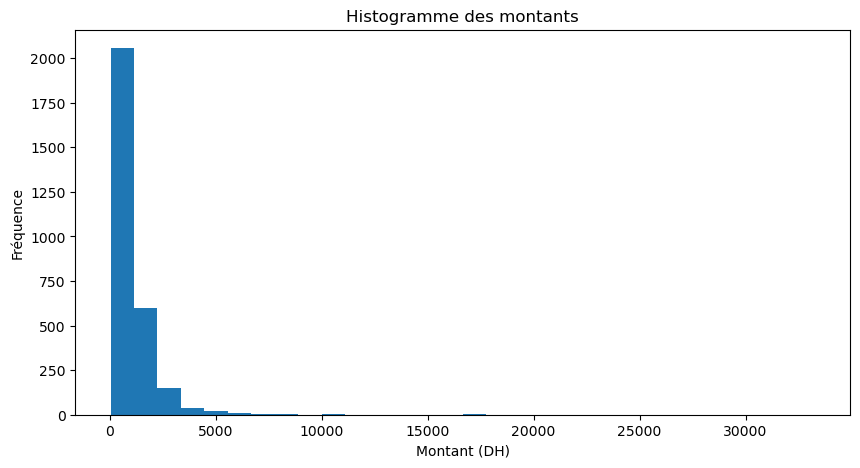

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.hist(df["montant_dh"].dropna(), bins=30)
plt.title("Histogramme des montants")
plt.xlabel("Montant (DH)")
plt.ylabel("Fréquence")
plt.show()

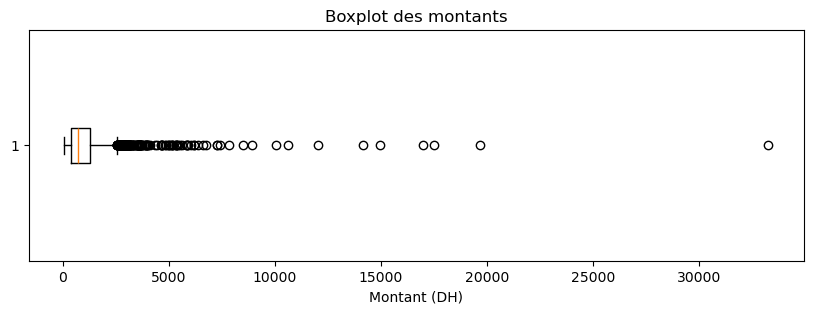

In [17]:
plt.figure(figsize=(10, 3))
plt.boxplot(df["montant_dh"].dropna(), vert=False)
plt.title("Boxplot des montants")
plt.xlabel("Montant (DH)")
plt.show()

In [149]:
Q1 = df["montant_dh"].quantile(0.25)
Q3 = df["montant_dh"].quantile(0.75)
IQR = Q3 - Q1
low = Q1 - 1.5 * IQR
upp = Q3 + 1.5 * IQR
print("[",low,",",upp,"]")                                        # min (-) makeynch chi montant negative ri calcule math!!! 

[ -900.3950000000002 , 2539.405 ]


In [19]:
montant_extreme = df[(df["montant_dh"] < low) |(df["montant_dh"] > upp)]
print(montant_extreme.shape)
print(montant_extreme["montant_dh"])

(184, 12)
0        5396.62
2        2846.79
32      10598.93
45       2943.87
65      14135.85
          ...   
2895     2620.30
2925     3909.57
2975     2983.78
3006     3134.54
3012     2718.89
Name: montant_dh, Length: 184, dtype: float64


In [21]:
#5

In [22]:
df["fraude"].value_counts()

fraude
0    2742
1     258
Name: count, dtype: int64

In [23]:
df["fraude"].value_counts(normalize=True)*100             

fraude
0    91.4
1     8.6
Name: proportion, dtype: float64

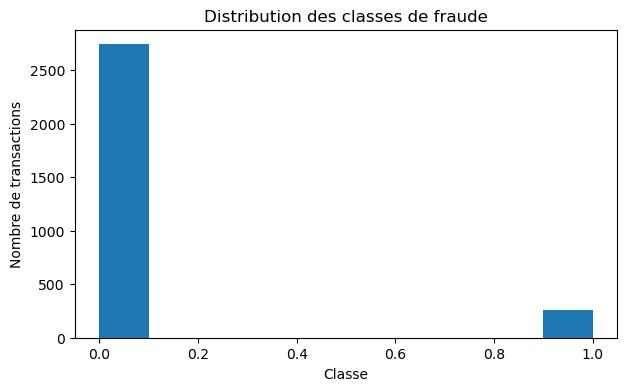

In [24]:
plt.figure(figsize=(7, 4))
plt.hist(df["fraude"])
plt.title("Distribution des classes de fraude")
plt.xlabel("Classe")
plt.ylabel("Nombre de transactions")
plt.show()

In [26]:
#6

In [28]:
#Partie 2 — Préparer les données sans fuite

In [29]:
#7 

In [30]:
X = df.drop(columns=[                  
    "id_operation",
    "id_client",
    "resultat_enquete",
    "fraude"
])
y = df["fraude"]

In [31]:
#8

In [150]:
from sklearn.model_selection import train_test_split
X_ref, X_verif, y_ref, y_verif = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

In [151]:
print("reference",y_ref.value_counts(normalize=True)*100)
print("\nverification",y_verif.value_counts(normalize=True)*100)

reference fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

verification fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


In [35]:
#9

In [36]:
X_ref.dtypes

montant_dh         float64
anciennete_mois    float64
nb_ops_24h         float64
heure                int64
canal               object
appareil            object
region              object
international       object
dtype: object

In [38]:
#10

In [39]:
from sklearn.impute import SimpleImputer 
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler 

numeric_pipe = make_pipeline(SimpleImputer(strategy="median"),StandardScaler()) 

In [40]:
#11

In [41]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipe = make_pipeline(SimpleImputer(strategy="most_frequent"),OneHotEncoder(handle_unknown="ignore"))  

In [42]:
#12

In [43]:
numeric = ["montant_dh","anciennete_mois","nb_ops_24h","heure"]
categorical = ["canal", "appareil", "region", "international"]

In [44]:
from sklearn.compose import ColumnTransformer
prep = ColumnTransformer([
    ("num", numeric_pipe, numeric),                         
    ("cat", categorical_pipe, categorical)])
X_ref_prep = prep.fit_transform(X_ref)
X_verif_prep = prep.transform(X_verif)

In [45]:
print("référence :", X_ref_prep.shape)
print("vérification :", X_verif_prep.shape)

référence : (2400, 18)
vérification : (600, 18)


In [47]:
#13 

In [48]:
from sklearn.preprocessing import RobustScaler

In [49]:
montants = X_ref[["montant_dh"]].dropna()

median = X_ref["montant_dh"].median()
maximum = X_ref["montant_dh"].max()

print("StandardScaler :")
print(StandardScaler().fit(montants).transform([[median], [maximum]]))

print("RobustScaler :")
print(RobustScaler().fit(montants).transform([[median], [maximum]]))

StandardScaler :
[[-0.23805897]
 [23.86583016]]
RobustScaler :
[[ 0.        ]
 [38.01482873]]


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(


In [51]:
#14

In [53]:
#Partie 3 — Comparer les méthodes de mise à l’échelle

In [54]:
#15

In [55]:
Q1 = X_ref["montant_dh"].quantile(0.25)
Q3 = X_ref["montant_dh"].quantile(0.75)
IQR = Q3-Q1
print("Q1 :",Q1)
print("Q3 :",Q3)
print("IQR :",IQR)

Q1 : 393.095
Q3 : 1249.8775
IQR : 856.7825


In [57]:
#16

In [58]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower :", lower)
print("Upper :", upper)

Lower : -892.0787499999999
Upper : 2535.05125


In [59]:
extreme = X_ref[
    (X_ref["montant_dh"] < lower) |
    (X_ref["montant_dh"] > upper)
]
print("Nombre de lignes :", extreme.shape[0])

Nombre de lignes : 146


In [61]:
#17 

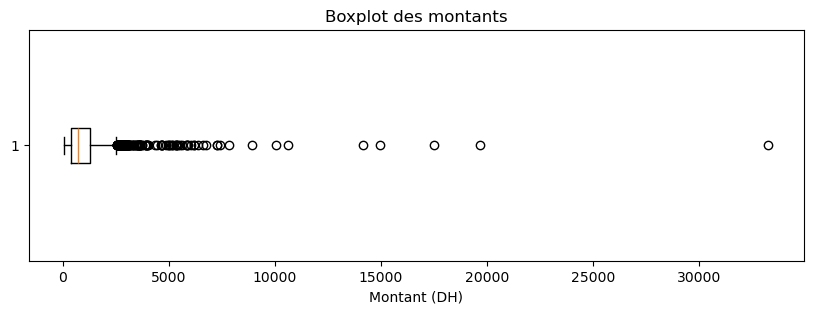

In [62]:
plt.figure(figsize=(10, 3))
plt.boxplot(X_ref["montant_dh"].dropna(), vert=False)
plt.title("Boxplot des montants")
plt.xlabel("Montant (DH)")
plt.show()

In [63]:
montants_limites = X_ref["montant_dh"].clip(
    lower=lower,
    upper=upper
).dropna()

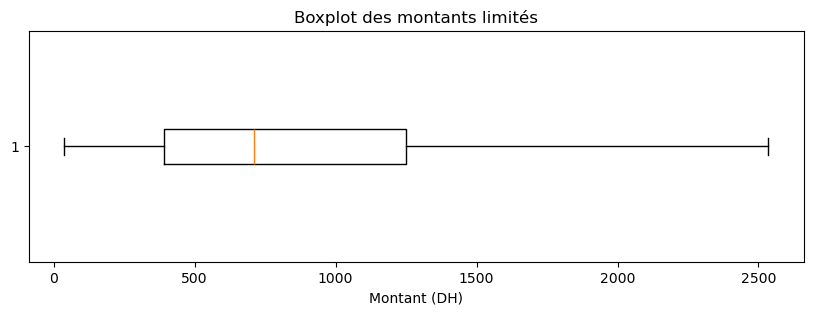

In [64]:
plt.figure(figsize=(10, 3))
plt.boxplot(montants_limites.dropna(), vert=False)
plt.title("Boxplot des montants limités")
plt.xlabel("Montant (DH)")
plt.show()

In [66]:
#18

In [67]:
from sklearn.preprocessing import MinMaxScaler
montants_ref = X_ref[["montant_dh"]]
montants_verif = X_verif[["montant_dh"]]
minmax = MinMaxScaler()
ref_minmax = minmax.fit_transform(montants_ref)
verif_minmax = minmax.transform(montants_verif)

In [68]:
standard = StandardScaler()

ref_standard = standard.fit_transform(montants_ref)
verif_standard = standard.transform(montants_verif)

In [69]:
robust = RobustScaler()

ref_robust = robust.fit_transform(montants_ref)
verif_robust = robust.transform(montants_verif)

In [70]:
#19

In [71]:
montants = X_ref["montant_dh"].dropna()

valeurs = [
    montants.quantile(0.25),
    montants.median(),
    montants.quantile(0.75),
    montants.max()
]

valeurs_df = pd.DataFrame({"montant_dh": valeurs})

minmax_values = minmax.transform(valeurs_df)
standard_values = standard.transform(valeurs_df)
robust_values = robust.transform(valeurs_df)
tableau = pd.DataFrame({
    "Montant original": valeurs,
    "MinMaxScaler": minmax_values.flatten(),
    "StandardScaler": standard_values.flatten(),
    "RobustScaler": robust_values.flatten()
})

print(tableau)

   Montant original  MinMaxScaler  StandardScaler  RobustScaler
0          393.0950      0.010729       -0.473170     -0.370800
1          710.7900      0.020285       -0.238059      0.000000
2         1249.8775      0.036501        0.160895      0.629200
3        33281.2300      1.000000       23.865830     38.014829


In [73]:
#20

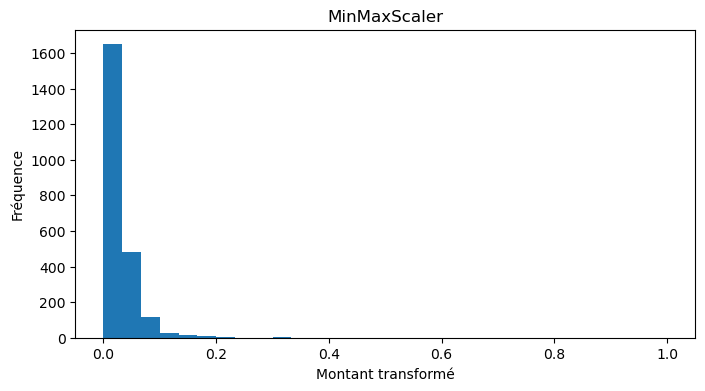

In [74]:
plt.figure(figsize=(8, 4))
plt.hist(ref_minmax, bins=30)
plt.title("MinMaxScaler")
plt.xlabel("Montant transformé")
plt.ylabel("Fréquence")
plt.show()

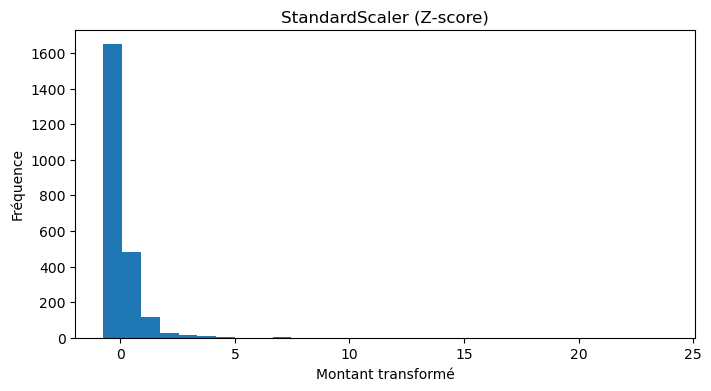

In [75]:
plt.figure(figsize=(8, 4))
plt.hist(ref_standard, bins=30)
plt.title("StandardScaler (Z-score)")
plt.xlabel("Montant transformé")
plt.ylabel("Fréquence")
plt.show()

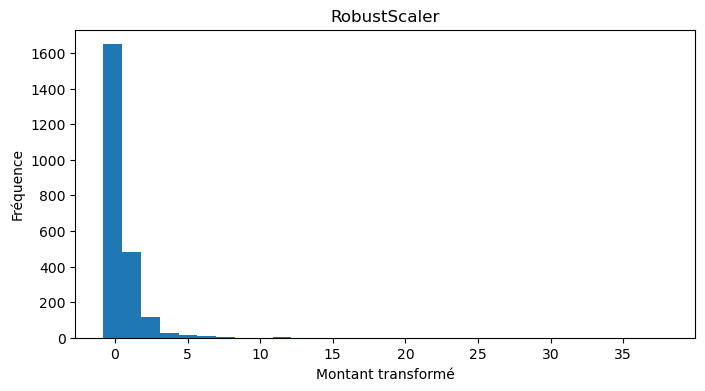

In [76]:
plt.figure(figsize=(8, 4))
plt.hist(ref_robust, bins=30)
plt.title("RobustScaler")
plt.xlabel("Montant transformé")
plt.ylabel("Fréquence")
plt.show()

In [78]:
#21

In [79]:
X_ref_test = [[200], [250], [600], [480], [700]]

scaler = MinMaxScaler()
scaler.fit(X_ref_test)
nouvelle_transaction = [[1500]]
resultat = scaler.transform(nouvelle_transaction)
print(resultat)

[[2.6]]


In [81]:
#Partie 4 — Préparer des classes déséquilibrées

In [82]:
#22

In [83]:
y_ref.value_counts()

fraude
0    2194
1     206
Name: count, dtype: int64

In [85]:
counts = y_ref.value_counts()

rapport = counts[0] / counts[1]

print("Rapport :", rapport)

Rapport : 10.650485436893204


In [87]:
#23 

In [88]:
print("Avant Oversampling :")
print(y_ref.value_counts())

Avant Oversampling :
fraude
0    2194
1     206
Name: count, dtype: int64


In [89]:
from imblearn.over_sampling import RandomOverSampler
random_ovs = RandomOverSampler(random_state=42)

X_ref_overs, y_ref_overs = random_ovs.fit_resample(X_ref, y_ref)

In [90]:
print("Après Oversampling :")
y_ref_overs.value_counts()

Après Oversampling :


fraude
0    2194
1    2194
Name: count, dtype: int64

In [94]:
#24

In [95]:
print("Avant Undersampling :")
print(y_ref.value_counts())

Avant Undersampling :
fraude
0    2194
1     206
Name: count, dtype: int64


In [96]:
from imblearn.under_sampling import RandomUnderSampler

random_under = RandomUnderSampler(random_state=42)
X_ref_under, y_ref_under = random_under.fit_resample(X_ref, y_ref)
print("Après Undersampling :")

print(y_ref_under.value_counts())

Après Undersampling :
fraude
0    206
1    206
Name: count, dtype: int64


In [98]:
#25

In [99]:
Xs = pd.DataFrame({
    "montant_dh": [1000, 2000, 1500, 1800, 1200, 2500, 3000, 3500],
    "nb_ops_24h": [2, 6, 3, 5, 2, 1, 4, 7]
})

ys = [1, 1, 1, 0, 0, 0, 0, 0]
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42, k_neighbors=2)

X_smote, y_smote = smote.fit_resample(Xs, ys)

ys = pd.Series(ys)                                
print("Observations réelles :")
print(Xs[ys == 1])

print("\nObservations synthétiques :")
print(X_smote.iloc[len(Xs):])                     

Observations réelles :
   montant_dh  nb_ops_24h
0        1000           2
1        2000           6
2        1500           3

Observations synthétiques :
   montant_dh  nb_ops_24h
8        1816           5
9        1110           2


In [101]:
#26

In [103]:
#27

In [104]:
tableau = pd.DataFrame({
    "Avant rééquilibrage": y_ref.value_counts(),
    "Après Oversampling": y_ref_overs.value_counts(),
    "Après Undersampling": y_ref_under.value_counts()
})

print(tableau)

        Avant rééquilibrage  Après Oversampling  Après Undersampling
fraude                                                              
0                      2194                2194                  206
1                       206                2194                  206


In [106]:
#Partie 5 — Vérifier et enregistrer les données préparées

In [107]:
#28

In [108]:
numeric_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    RobustScaler()
)
categorical_pipe = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore")
)
prep_final = ColumnTransformer([
    ("num", numeric_pipe, numeric),
    ("cat", categorical_pipe, categorical)
])

In [109]:
#29

In [110]:
X_ref_final = prep_final.fit_transform(X_ref)
X_verif_final = prep_final.transform(X_verif)

In [111]:
print("Nombre de lignes Référence :", X_ref_final.shape)
print("Nombre de lignes Vérification :", X_verif_final.shape)

Nombre de lignes Référence : (2400, 18)
Nombre de lignes Vérification : (600, 18)


In [112]:
print("Valeurs manquantes dans référence :", pd.isna(X_ref_final).sum()) 
print("Valeurs manquantes dans vérification :", pd.isna(X_verif_final).sum())

Valeurs manquantes dans référence : 0
Valeurs manquantes dans vérification : 0


In [113]:
#30

In [114]:
nouvelle_operation = pd.DataFrame([{
    "montant_dh": 1500,                                 
    "anciennete_mois": 12,
    "nb_ops_24h": 3,
    "heure": 14,
    "canal": "guichet",
    "appareil": "mobile",
    "region": "Draa-Tafilalet",
    "international": "non"
}])
nouvelle_operation_transformee = prep_final.transform(nouvelle_operation)                  

print("Nombre de colonnes :", nouvelle_operation_transformee.shape[1])                 

Nombre de colonnes : 18


In [116]:
#31

In [117]:
import numpy as np
import joblib
joblib.dump(prep_final, "preprocessor_final.pkl") 

['preprocessor_final.pkl']

In [118]:
prep_loaded = joblib.load("preprocessor_final.pkl") 

In [119]:
echantillon = X_ref.head(5)
resultat_original = prep_final.transform(echantillon)
resultat_charge = prep_loaded.transform(echantillon)

In [120]:
print(np.allclose(resultat_original, resultat_charge))

True


In [122]:
#32

In [122]:
#Facultative 

In [140]:
print("Moyenne :", X_ref["montant_dh"].mean())
print("Médiane :", X_ref["montant_dh"].median())

Moyenne : 1032.467776816609
Médiane : 710.79


In [147]:
from imblearn.over_sampling import SMOTENC

X_mixte = pd.DataFrame({
    "montant_dh": [1000, 2500, 1200, 3000, 1500],
    "canal": ["mobile", "guichet", "internet", "guichet", "mobile"]
})
y_mixte = pd.Series([1, 1, 0, 0, 0])                                              
smote_nc = SMOTENC(categorical_features=[1], random_state=42, k_neighbors=1)      
X_nouveau, y_nouveau = smote_nc.fit_resample(X_mixte, y_mixte)                   
print("Les observations générées par SMOTENC :")
print(X_nouveau)

Les observations générées par SMOTENC :
   montant_dh     canal
0        1000    mobile
1        2500   guichet
2        1200  internet
3        3000   guichet
4        1500    mobile
5        2194   guichet
